<a href="https://colab.research.google.com/github/Team-JAZL/Fruitects-IS-DPC/blob/feat%2Fintelligent-systems-model-preparation/benchmarking/fruit_type_identifier_model_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install kaggle library
!pip install -q kaggle

# Create kaggle directory and move the uploaded json file there
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the specific dataset
!kaggle datasets download -d muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten

# Unzip the downloaded dataset
!unzip -q fruit-and-vegetable-disease-healthy-vs-rotten.zip -d raw_dataset
print("Dataset downloaded and extracted successfully!")

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten
License(s): CC0-1.0
100%|███████████████████████████████████████| 4.77G/4.77G [00:23<00:00, 222MB/s]

Dataset downloaded and extracted successfully!


In [2]:
import os
import shutil

source_dir = '/kaggle/working/raw_dataset/Fruit And Vegetable Diseases Dataset'
base_dest_dir = '/kaggle/working/organized_fruit_dataset'

# Mapping the specific folder names to the target Fruit class
target_mapping = {
    'Apple': ['apple__healthy', 'apple__rotten'],
    'Guava': ['guava__healthy', 'guava__rotten'],
    'Mango': ['mango__healthy', 'mango__rotten']
}

# Create the new directory structure in the working folder
for fruit in target_mapping.keys():
    os.makedirs(os.path.join(base_dest_dir, fruit), exist_ok=True)

image_count = {'Apple': 0, 'Guava': 0, 'Mango': 0}

# Walk through the attached dataset
for root, dirs, files in os.walk(source_dir):
    folder_name = os.path.basename(root).lower()
    
    # Check if the current folder matches any of our target keywords
    for target_fruit, folder_keywords in target_mapping.items():
        if any(keyword in folder_name for keyword in folder_keywords):
            for file in files:
                if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                    file_path = os.path.join(root, file)
                    
                    # Append folder name to avoid duplicate file names
                    unique_filename = f"{folder_name}_{file}"
                    dest_path = os.path.join(base_dest_dir, target_fruit, unique_filename)
                    shutil.copy2(file_path, dest_path)
                    image_count[target_fruit] += 1
            break # Move to next folder once categorized

print("Data successfully reorganized into working directory!")
print(f"Images copied: {image_count}")

Data successfully reorganized into working directory!
Images copied: {'Apple': 5363, 'Guava': 400, 'Mango': 4060}


In [3]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 42

# Create a full dataset
print("Loading Training Data...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3, # 70% for training, 30% for val/test
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("\nLoading Validation/Test Data...")
val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_dataset.class_names
print(f"\nClasses identified: {class_names}")

# Split the 30% validation pool evenly into Validation (15%) and Testing (15%)
val_batches = tf.data.experimental.cardinality(val_test_dataset)
val_dataset = val_test_dataset.take(val_batches // 2)
test_dataset = val_test_dataset.skip(val_batches // 2)

# Optimize performance
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

2026-04-26 12:14:44.545844: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1777205684.757488      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1777205684.817848      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1777205685.267153      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777205685.267197      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1777205685.267200      55 computation_placer.cc:177] computation placer alr

Loading Training Data...
Found 9823 files belonging to 3 classes.
Using 6877 files for training.


I0000 00:00:1777205712.466268      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0



Loading Validation/Test Data...
Found 9823 files belonging to 3 classes.
Using 2946 files for validation.

Classes identified: ['Apple', 'Guava', 'Mango']


In [4]:
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_model(base_model_type, num_classes):
    input_shape = IMG_SIZE + (3,)

    if base_model_type == 'resnet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
        # ResNet50 requires specific preprocessing
        preprocess_input = tf.keras.applications.resnet50.preprocess_input
    elif base_model_type == 'mobilenetv2':
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
        # MobileNetV2 requires inputs between [-1, 1]
        preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
    else:
        raise ValueError("Invalid model type")

    # Freeze the base model
    base_model.trainable = False

    # Create the model architecture
    inputs = tf.keras.Input(shape=input_shape)
    x = preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)

    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

resnet_model = build_model('resnet50', len(class_names))
mobilenet_model = build_model('mobilenetv2', len(class_names))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


--- Training ResNet-50 ---
Epoch 1/10


I0000 00:00:1777205736.581196     141 service.cc:152] XLA service 0x7e25b8003ce0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1777205736.581228     141 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1777205738.410343     141 cuda_dnn.cc:529] Loaded cuDNN version 91002


  3/215 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.5208 - loss: 1.5318    

I0000 00:00:1777205742.712030     141 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


215/215 ━━━━━━━━━━━━━━━━━━━━ 47s 105ms/step - accuracy: 0.8928 - loss: 0.2952 - val_accuracy: 0.9912 - val_loss: 0.0358
Epoch 2/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9911 - loss: 0.0339 - val_accuracy: 0.9952 - val_loss: 0.0217
Epoch 3/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9951 - loss: 0.0246 - val_accuracy: 0.9959 - val_loss: 0.0156
Epoch 4/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9978 - loss: 0.0121 - val_accuracy: 0.9959 - val_loss: 0.0132
Epoch 5/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9966 - loss: 0.0121 - val_accuracy: 0.9966 - val_loss: 0.0109
Epoch 6/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9993 - loss: 0.0074 - val_accuracy: 0.9973 - val_loss: 0.0094
Epoch 7/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9991 - loss: 0.0066 - val_accuracy: 0.9993 - val_loss: 0.0071
Epoch 8/10
215/215 ━━━━━━━━━━━━━━━━━━━━ 11s 53ms/step - accuracy: 0.9996 - loss: 0.0050 - val_accura

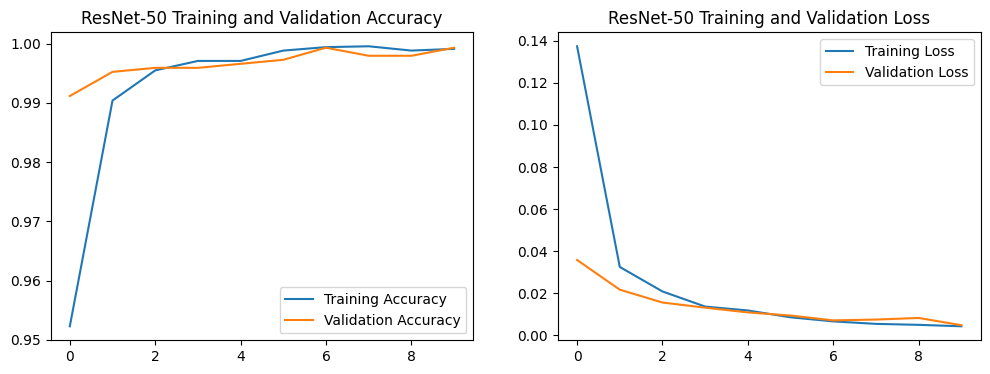

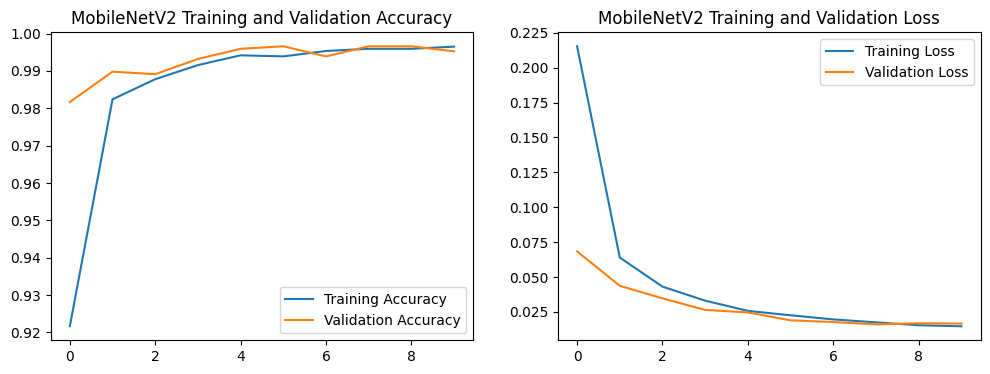

In [5]:
import matplotlib.pyplot as plt

EPOCHS = 10

print("--- Training ResNet-50 ---")
resnet_history = resnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

print("\n--- Training MobileNetV2 ---")
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

# Function to plot training results
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(EPOCHS)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{model_name} Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{model_name} Training and Validation Loss')
    plt.show()

plot_history(resnet_history, 'ResNet-50')
plot_history(mobilenet_history, 'MobileNetV2')


Evaluating ResNet-50...

--- ResNet-50 Benchmark Results ---
Test Accuracy: 0.9993
Test Loss: 0.0038
Average Inference Latency per image: 55.04 ms

Classification Report:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00       803
       Guava       1.00      1.00      1.00        62
       Mango       1.00      1.00      1.00       609

    accuracy                           1.00      1474
   macro avg       1.00      1.00      1.00      1474
weighted avg       1.00      1.00      1.00      1474



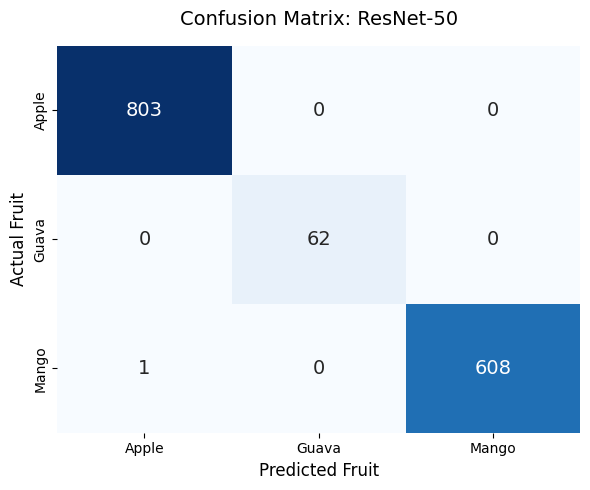


Evaluating MobileNetV2...

--- MobileNetV2 Benchmark Results ---
Test Accuracy: 0.9966
Test Loss: 0.0123
Average Inference Latency per image: 72.13 ms

Classification Report:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00       803
       Guava       1.00      1.00      1.00        62
       Mango       0.99      1.00      1.00       609

    accuracy                           1.00      1474
   macro avg       1.00      1.00      1.00      1474
weighted avg       1.00      1.00      1.00      1474



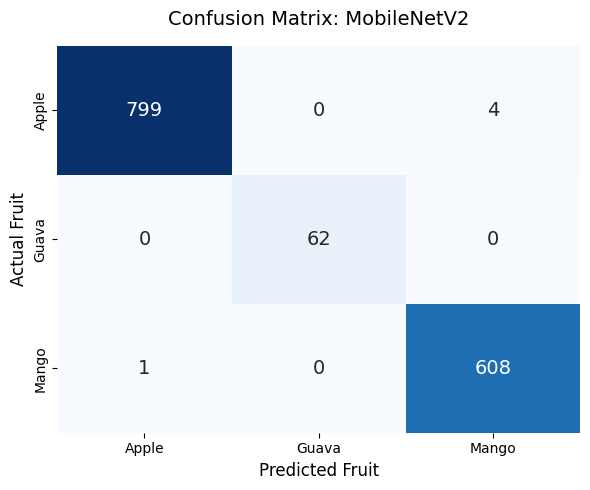

In [6]:
import time
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, dataset, model_name):
    print(f"\n{'='*40}")
    print(f"Evaluating {model_name}...")
    print(f"{'='*40}")

    y_true = []
    y_pred = []
    latencies = []

    # Calculate Latency & get predictions
    for images, labels in dataset:
        y_true.extend(labels.numpy())

        # Measure inference latency per batch
        start_time = time.time()
        preds = model.predict(images, verbose=0)
        end_time = time.time()

        # Latency per image in milliseconds
        batch_latency = (end_time - start_time) / len(images) * 1000
        latencies.append(batch_latency)

        y_pred.extend(np.argmax(preds, axis=1))

    # Calculate standard metrics
    loss, accuracy = model.evaluate(dataset, verbose=0)
    avg_latency = np.mean(latencies)

    print(f"\n--- {model_name} Benchmark Results ---")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Test Loss: {loss:.4f}")
    print(f"Average Inference Latency per image: {avg_latency:.2f} ms")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Generate and Plot the Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names,
                cbar=False,
                annot_kws={"size": 14})

    plt.title(f'Confusion Matrix: {model_name}', fontsize=14, pad=15)
    plt.ylabel('Actual Fruit', fontsize=12)
    plt.xlabel('Predicted Fruit', fontsize=12)
    plt.tight_layout()
    plt.show()

    return accuracy, loss

# Run evaluation and capture the return values for the next cell
resnet_acc, resnet_loss = evaluate_model(resnet_model, test_dataset, "ResNet-50")
mobilenet_acc, mobilenet_loss = evaluate_model(mobilenet_model, test_dataset, "MobileNetV2")

In [7]:
import os

print("--- Selecting the Best Model ---")

# Extract final test metrics for both models
resnet_loss, resnet_acc = resnet_model.evaluate(test_dataset, verbose=0)
print(f"ResNet-50 Test Accuracy: {resnet_acc:.4f} (Loss: {resnet_loss:.4f})")

mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(test_dataset, verbose=0)
print(f"MobileNetV2 Test Accuracy: {mobilenet_acc:.4f} (Loss: {mobilenet_loss:.4f})")

# Determine the winner
if mobilenet_acc > resnet_acc:
    print("\n🏆 MobileNetV2 is the better model based on accuracy.")
    best_model = mobilenet_model
    best_model_name = "/kaggle/working/fruit_type_identifier_mobilenetv2.keras"
elif resnet_acc > mobilenet_acc:
    print("\n🏆 ResNet-50 is the better model based on accuracy.")
    best_model = resnet_model
    best_model_name = "/kaggle/working/fruit_type_identifier_resnet50.keras"
else:
    # Tie-breaker based on lowest validation loss
    if mobilenet_loss < resnet_loss:
        print("\n🏆 Models tied on accuracy. MobileNetV2 selected based on lower loss.")
        best_model = mobilenet_model
        best_model_name = "/kaggle/working/fruit_type_identifier_mobilenetv2.keras"
    else:
        print("\n🏆 Models tied on accuracy. ResNet-50 selected based on lower loss.")
        best_model = resnet_model
        best_model_name = "/kaggle/working/fruit_type_identifier_resnet50.keras"

# Save the winning model
best_model.save(best_model_name)
print(f"\nModel successfully saved as: '{best_model_name}'")

# Check file size of the saved model
file_size_mb = os.path.getsize(best_model_name) / (1024 * 1024)
print(f"Saved model file size: {file_size_mb:.2f} MB")

--- Selecting the Best Model ---
ResNet-50 Test Accuracy: 0.9993 (Loss: 0.0038)
MobileNetV2 Test Accuracy: 0.9966 (Loss: 0.0123)

🏆 ResNet-50 is the better model based on accuracy.

Model successfully saved as: '/kaggle/working/fruit_type_identifier_resnet50.keras'
Saved model file size: 90.68 MB
